# 🚀 Training & Evaluation Benchmark: Monocular Depth Estimation on SUN RGB-D
**Course:** CO3133 – Deep Learning & Applications  
**Project:** BTL2 – Monocular Depth Estimation with Real-World Indoor Scenes  
**Dataset:** SUN RGB-D (10,335 Aligned Pairs, Ground Truth: `depth_bfx`)  
**Target Environment:** Kaggle (GPU P100 / 2x T4) & Google Colab (L4 / T4)

---

### 🔬 Overview of Experimental Design (4 Scientific Experiments)
To thoroughly evaluate the paradigm shift from classical Convolutional Neural Networks to modern Vision Transformer Foundation Models, this notebook executes **4 controlled experiments**:

| Experiment | Model Architecture | Training Strategy | Scientific Objective |
| :--- | :--- | :--- | :--- |
| **E0** | **Depth Anything V2 (Small - ViT)** | **Pretrained Inference (Zero-shot)** | Measure zero-shot out-of-the-box generalization without seeing SUN RGB-D. |
| **E1** | **Simple Custom CNN U-Net** | **Trained from scratch** (Random init, 20 epochs) | Establish baseline performance without pretrained knowledge. |
| **E2** | **Depth Anything V2 (Small - ViT)** | **Freeze Encoder, Train Depth Head only** (15 epochs) | Measure spatial representation power of pretrained ViT backbone (Linear Probing). |
| **E3** | **Depth Anything V2 (Small - ViT)** | **Full Fine-Tuning (Encoder + Head)** (15 epochs) | End-to-end domain adaptation for SOTA sharp indoor metric depth. |

* **Objective Function:** Combined **Scale-Invariant Logarithmic Error (SILog)** and **Gradient Edge Loss**:
  $$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{SILog}} + 0.5 \cdot \mathcal{L}_{\text{grad}}$$
* **Resilience:** Built-in **3-layer Fault Tolerance (Auto-Resume from checkpoints & Auto-Skip completed experiments)**.


## 1. Environment Configuration & Hardware Diagnostics


In [1]:
# ==============================================================================
# BLOCK 1: AUTOMATIC ENVIRONMENT & HARDWARE DETECTION
# ==============================================================================
import os, sys, glob, shutil, time, json, random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Check Execution Platform (Kaggle vs Colab vs Local)
IS_KAGGLE = os.path.exists('/kaggle')
IS_COLAB = 'google.colab' in sys.modules

print("=" * 70)
print(f"🌍 Platform Detected: {'KAGGLE' if IS_KAGGLE else ('GOOGLE COLAB' if IS_COLAB else 'LOCAL WORKSPACE')}")
print("=" * 70)

# Configure Directories & Google Drive Source dynamically
GDRIVE_FILE_ID = "1qSyp_1jmMne4yv6iPdm14fHYkBi-XAfK"

if IS_KAGGLE:
    WORKING_DIR = '/kaggle/working'
    OUTPUT_DIR = os.path.join(WORKING_DIR, 'outputs')
    CKPT_DIR = os.path.join(WORKING_DIR, 'checkpoints')
    
    # Check if dataset is already unpacked in /tmp/sunrgbd
    DATA_DIR = '/tmp/sunrgbd'
    if not os.path.exists(DATA_DIR) or len(os.listdir(DATA_DIR)) == 0:
        # 1. Check if user mounted a Kaggle Dataset input
        possible_roots = glob.glob('/kaggle/input/**/depth_bfx', recursive=True) + glob.glob('/kaggle/input/**/depth', recursive=True)
        zips = glob.glob('/kaggle/input/**/*.zip', recursive=True)
        if possible_roots:
            DATA_DIR = str(Path(possible_roots[0]).parent.parent)
            print(f"📦 Đã tìm thấy dataset trong Kaggle Input: {DATA_DIR}")
        elif zips:
            zip_path = zips[0]
            print(f"📦 Đang giải nén zip từ Kaggle Input ({zip_path}) vào /tmp/sunrgbd...")
            os.makedirs(DATA_DIR, exist_ok=True)
            os.system(f'unzip -q "{zip_path}" -d {DATA_DIR}')
        else:
            # 2. Auto-fetch directly from Google Drive via gdown
            print(f"🌐 Chưa có dataset trong Kaggle Input. Tự động kéo SUNRGBD.zip trực tiếp từ Google Drive (ID: {GDRIVE_FILE_ID})...")
            zip_tmp = '/tmp/SUNRGBD.zip'
            if not os.path.exists(zip_tmp) or os.path.getsize(zip_tmp) < 1024 * 1024:
                os.system('pip install -q gdown')
                os.system(f'gdown --id {GDRIVE_FILE_ID} -O {zip_tmp}')
            
            print("📦 Đang giải nén dữ liệu vào ổ cứng siêu tốc (/tmp/sunrgbd)...")
            os.makedirs(DATA_DIR, exist_ok=True)
            os.system(f'unzip -q "{zip_tmp}" -d {DATA_DIR}')
    else:
        print(f"✅ Dữ liệu đã sẵn sàng trong: {DATA_DIR}")

elif IS_COLAB:
    from google.colab import drive
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')
    WORKING_DIR = '/content'
    OUTPUT_DIR = '/content/drive/MyDrive/BTL-deep_learning/assignment2/outputs'
    CKPT_DIR = '/content/drive/MyDrive/BTL-deep_learning/assignment2/checkpoints'
    DATA_DIR = '/content/sunrgbd'
    
    # Giải nén vào Colab SSD cục bộ để tăng tốc dataloading gấp 10 lần
    if not os.path.exists(DATA_DIR) or len(os.listdir(DATA_DIR)) == 0:
        drive_zip = '/content/drive/MyDrive/BTL-deep_learning/assignment2/datasets/SUNRGBD.zip'
        if os.path.exists(drive_zip):
            print(f"📦 Đang giải nén từ Drive {drive_zip} vào SSD Colab...")
            os.makedirs(DATA_DIR, exist_ok=True)
            os.system(f'unzip -q "{drive_zip}" -d {DATA_DIR}')
        else:
            print(f"📥 Đang tải từ link Google Drive (ID: {GDRIVE_FILE_ID})...")
            os.system(f'gdown --id {GDRIVE_FILE_ID} -O /content/SUNRGBD.zip')
            os.makedirs(DATA_DIR, exist_ok=True)
            os.system(f'unzip -q /content/SUNRGBD.zip -d {DATA_DIR}')
else:
    WORKING_DIR = '.'
    OUTPUT_DIR = './outputs'
    CKPT_DIR = './checkpoints'
    DATA_DIR = './data/sunrgbd'

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(CKPT_DIR, exist_ok=True)

print(f"📂 Working Root:    {WORKING_DIR}")
print(f"📂 Dataset Root:    {DATA_DIR}")
print(f"📂 Checkpoint Dir:  {CKPT_DIR}")
print(f"📂 Outputs Dir:     {OUTPUT_DIR}")

# Hardware Accelerator
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"⚡ PyTorch Version: {torch.__version__}")
print(f"⚡ Device:          {device}")
if torch.cuda.is_available():
    print(f"   GPU Name:       {torch.cuda.get_device_name(0)}")
    print(f"   VRAM Total:     {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    print(f"   CUDA Capability:{torch.cuda.get_device_capability(0)}")

# Deterministic Seed
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(42)
print("🎲 Random Seed locked to: 42")


🌍 Platform Detected: KAGGLE
🌐 Chưa có dataset trong Kaggle Input. Tự động kéo SUNRGBD.zip trực tiếp từ Google Drive (ID: 1qSyp_1jmMne4yv6iPdm14fHYkBi-XAfK)...


/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1qSyp_1jmMne4yv6iPdm14fHYkBi-XAfK
From (redirected): https://drive.google.com/uc?id=1qSyp_1jmMne4yv6iPdm14fHYkBi-XAfK&confirm=t&uuid=cf4086ec-c11b-43be-b375-b2dd3090145d
To: /tmp/SUNRGBD.zip
100%|██████████| 6.89G/6.89G [01:51<00:00, 61.8MB/s]


📦 Đang giải nén dữ liệu vào ổ cứng siêu tốc (/tmp/sunrgbd)...
📂 Working Root:    /kaggle/working
📂 Dataset Root:    /tmp/sunrgbd
📂 Checkpoint Dir:  /kaggle/working/checkpoints
📂 Outputs Dir:     /kaggle/working/outputs
⚡ PyTorch Version: 2.11.0+cu128
⚡ Device:          cuda
   GPU Name:       Tesla T4
   VRAM Total:     14.56 GB
   CUDA Capability:(7, 5)
🎲 Random Seed locked to: 42


## 2. Dependencies & Foundation Model (Depth Anything V2) Setup


In [2]:
# ==============================================================================
# BLOCK 2: DEPTH ANYTHING V2 REPOSITORY & PRETRAINED WEIGHTS
# ==============================================================================
# Clone Depth Anything V2 repository if not cloned
repo_path = os.path.join(WORKING_DIR, "Depth-Anything-V2")
if not os.path.exists(repo_path):
    print("📥 Cloning Depth-Anything-V2 repository from GitHub...")
    !git clone https://github.com/DepthAnything/Depth-Anything-V2.git {repo_path}

metric_depth_path = os.path.join(repo_path, "metric_depth")
if metric_depth_path not in sys.path:
    sys.path.append(metric_depth_path)

# Download Depth Anything V2 Small Metric Pretrained Weights (Indoor Hypersim)
vits_weights_path = os.path.join(WORKING_DIR, "depth_anything_v2_metric_hypersim_vits.pth")
if not os.path.exists(vits_weights_path):
    print("📥 Downloading Depth Anything V2 Small Metric Checkpoint (~98 MB)...")
    weights_url = "https://huggingface.co/depth-anything/Depth-Anything-V2-Metric-Hypersim-Small/resolve/main/depth_anything_v2_metric_hypersim_vits.pth"
    !curl -L -o {vits_weights_path} {weights_url}
else:
    print(f"✅ Found existing Depth Anything V2 weights: {vits_weights_path}")

print("✅ Depth-Anything-V2 environment configured successfully.")


📥 Cloning Depth-Anything-V2 repository from GitHub...
Cloning into '/kaggle/working/Depth-Anything-V2'...
remote: Enumerating objects: 146, done.
remote: Total 146 (delta 0), reused 0 (delta 0), pack-reused 146 (from 1)
Receiving objects: 100% (146/146), 45.18 MiB | 54.04 MiB/s, done.
Resolving deltas: 100% (45/45), done.
📥 Downloading Depth Anything V2 Small Metric Checkpoint (~98 MB)...
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100   968  100   968    0     0    944      0  0:00:01  0:00:01 --:--:--   945
100 94.6M  100 94.6M    0     0  41.9M      0  0:00:02  0:00:02 --:--:--  159M
✅ Depth-Anything-V2 environment configured successfully.


## 3. Dataset Acquisition, Manifest & Anti-Leakage Split
To prevent **Data Contamination (Scene Leakage)**, splitting is strictly constrained to **Disjoint Physical Rooms (Scene Identifiers)**. No frame from a room in Train is permitted to appear in Validation or Test.


In [3]:
# ==============================================================================
# BLOCK 3: MANIFEST GENERATION & ANTI-LEAKAGE DISJOINT SPLIT
# ==============================================================================
manifest_path = os.path.join(OUTPUT_DIR, "sunrgbd_manifest_10335.csv")

# Also look for pre-generated manifest in Kaggle / Colab input
possible_manifests = glob.glob('/kaggle/input/**/sunrgbd_manifest*.csv', recursive=True) + glob.glob('/content/**/sunrgbd_manifest*.csv', recursive=True)
if possible_manifests and not os.path.exists(manifest_path):
    manifest_path = possible_manifests[0]

df_manifest = None
if os.path.exists(manifest_path):
    temp_df = pd.read_csv(manifest_path)
    if len(temp_df) > 0 and os.path.exists(temp_df.iloc[0]["rgb_path"]):
        print(f"📄 Loading existing valid manifest from: {manifest_path}")
        df_manifest = temp_df
    else:
        print(f"⚠️ Manifest {manifest_path} chứa đường dẫn môi trường khác. Tự động quét lại máy cục bộ...")

if df_manifest is None:
    print(f"🔍 Scanning directory {DATA_DIR} to generate master manifest...")
    root = Path(DATA_DIR)
    scene_dirs = sorted([p.parent for p in root.rglob("depth") if p.is_dir()])
    records = []
    for scene in tqdm(scene_dirs, desc="Scanning scenes"):
        rgb_files = list((scene / "image").glob("*.jpg")) + list((scene / "image").glob("*.png"))
        raw_depth_files = list((scene / "depth").glob("*.png"))
        bfx_depth_files = list((scene / "depth_bfx").glob("*.png"))
        if rgb_files and (bfx_depth_files or raw_depth_files):
            records.append({
                "scene_id": str(scene.relative_to(root)),
                "rgb_path": str(rgb_files[0]),
                "depth_path": str(raw_depth_files[0]) if raw_depth_files else str(bfx_depth_files[0]),
                "depth_bfx_path": str(bfx_depth_files[0]) if bfx_depth_files else str(raw_depth_files[0])
            })
    df_manifest = pd.DataFrame(records)
    save_target = os.path.join(OUTPUT_DIR, "sunrgbd_manifest_10335.csv")
    df_manifest.to_csv(save_target, index=False)
    print(f"✅ Generated master manifest saved to: {save_target}")

print(f"📊 Total Available Pairs: {len(df_manifest):,}")
print(f"   Unique Scene Rooms:    {df_manifest['scene_id'].nunique():,}")

# -------------------------------------------------------------------------
# Anti-Leakage Split (Physical Room / Scene Disjoint Partition)
# -------------------------------------------------------------------------
unique_scenes = np.array(sorted(df_manifest['scene_id'].unique()))
rng = np.random.RandomState(42)
rng.shuffle(unique_scenes)

n_total = len(unique_scenes)
n_train = int(0.75 * n_total)
n_val = int(0.15 * n_total)

train_scenes = set(unique_scenes[:n_train])
val_scenes = set(unique_scenes[n_train:n_train + n_val])
test_scenes = set(unique_scenes[n_train + n_val:])

# Formally Assert Zero Data Leakage
assert len(train_scenes.intersection(val_scenes)) == 0, "FATAL: Scene leakage between Train and Val!"
assert len(train_scenes.intersection(test_scenes)) == 0, "FATAL: Scene leakage between Train and Test!"
assert len(val_scenes.intersection(test_scenes)) == 0, "FATAL: Scene leakage between Val and Test!"

df_train = df_manifest[df_manifest['scene_id'].isin(train_scenes)].reset_index(drop=True)
df_val = df_manifest[df_manifest['scene_id'].isin(val_scenes)].reset_index(drop=True)
df_test = df_manifest[df_manifest['scene_id'].isin(test_scenes)].reset_index(drop=True)

print("🔒 Anti-Leakage Scene Partition Summary:")
print(f"   Train Set: {len(df_train):,} pairs ({len(train_scenes):,} scenes, {len(df_train)/len(df_manifest)*100:.1f}%)")
print(f"   Val Set:   {len(df_val):,} pairs ({len(val_scenes):,} scenes, {len(df_val)/len(df_manifest)*100:.1f}%)")
print(f"   Test Set:  {len(df_test):,} pairs ({len(test_scenes):,} scenes, {len(df_test)/len(df_manifest)*100:.1f}%)")


🔍 Scanning directory /tmp/sunrgbd to generate master manifest...


Scanning scenes:   0%|          | 0/10335 [00:00<?, ?it/s]

✅ Generated master manifest saved to: /kaggle/working/outputs/sunrgbd_manifest_10335.csv
📊 Total Available Pairs: 10,335
   Unique Scene Rooms:    10,335
🔒 Anti-Leakage Scene Partition Summary:
   Train Set: 7,751 pairs (7,751 scenes, 75.0%)
   Val Set:   1,550 pairs (1,550 scenes, 15.0%)
   Test Set:  1,034 pairs (1,034 scenes, 10.0%)


## 4. PyTorch Dataset Pipeline with Deterministic Bit-Shift Decoding


In [4]:
# ==============================================================================
# BLOCK 4: PYTORCH DATASET WITH BIT-SHIFT DECODING & AUGMENTATION
# ==============================================================================
def decode_sunrgbd_depth(depth_raw):
    """
    Deterministic 16-bit PNG Bit-Shift Decoding (Princeton SUN RGB-D standard):
    (raw >> 3) | (raw << 13) -> millimetres -> / 1000.0 (meters)
    """
    decoded_mm = np.bitwise_or(np.right_shift(depth_raw, 3), np.left_shift(depth_raw, 13))
    return decoded_mm.astype(np.float32) / 1000.0

class SUNRGBDDataset(Dataset):
    def __init__(self, df, target_size=(256, 320), is_train=False):
        self.df = df
        self.target_h, self.target_w = target_size
        self.is_train = is_train
        # ImageNet normalization parameters
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        rgb_path = row['rgb_path']
        depth_path = row['depth_bfx_path']

        # 1. Read RGB Image
        img_bgr = cv2.imread(rgb_path)
        if img_bgr is None:
            raise FileNotFoundError(f"RGB image missing: {rgb_path}")
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # 2. Read 16-bit Ground Truth Depth
        depth_raw = cv2.imread(depth_path, cv2.IMREAD_ANYDEPTH)
        if depth_raw is None:
            raise FileNotFoundError(f"Depth map missing: {depth_path}")
        depth_m = decode_sunrgbd_depth(depth_raw)

        # 3. Synchronized Resizing
        # RGB uses bilinear; Depth uses nearest neighbor to prevent boundary interpolation artifacts
        img_resized = cv2.resize(img_rgb, (self.target_w, self.target_h), interpolation=cv2.INTER_LINEAR)
        depth_resized = cv2.resize(depth_m, (self.target_w, self.target_h), interpolation=cv2.INTER_NEAREST)

        # 4. Section 19.6 Validity Mask (0.5m <= Z <= 8.0m)
        valid_mask = (depth_resized >= 0.5) & (depth_resized <= 8.0) & np.isfinite(depth_resized)

        # 5. Training Augmentation
        if self.is_train:
            # Random horizontal flip synchronized across RGB, Depth, and Mask
            if random.random() > 0.5:
                img_resized = np.ascontiguousarray(np.fliplr(img_resized))
                depth_resized = np.ascontiguousarray(np.fliplr(depth_resized))
                valid_mask = np.ascontiguousarray(np.fliplr(valid_mask))
            # Random brightness jitter for RGB
            if random.random() > 0.5:
                scale = random.uniform(0.85, 1.15)
                img_resized = np.clip(img_resized.astype(np.float32) * scale, 0, 255).astype(np.uint8)

        # 6. Tensor Normalization & Channel Conversion
        img_norm = (img_resized.astype(np.float32) / 255.0 - self.mean) / self.std
        img_tensor = torch.from_numpy(img_norm.transpose(2, 0, 1)).float()
        depth_tensor = torch.from_numpy(depth_resized).unsqueeze(0).float()
        mask_tensor = torch.from_numpy(valid_mask).unsqueeze(0).bool()

        return img_tensor, depth_tensor, mask_tensor

# Hyperparameters
BATCH_SIZE = 16
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_dataset = SUNRGBDDataset(df_train, is_train=True)
val_dataset = SUNRGBDDataset(df_val, is_train=False)
test_dataset = SUNRGBDDataset(df_test, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

sample_img, sample_depth, sample_mask = next(iter(train_loader))
print(f"✅ DataLoaders initialized:")
print(f"   Batch Image Tensor: {sample_img.shape} (dtype: {sample_img.dtype})")
print(f"   Batch Depth Tensor: {sample_depth.shape} (dtype: {sample_depth.dtype})")
print(f"   Batch Mask Tensor:  {sample_mask.shape} (Valid Pixels: {sample_mask.sum().item():,})")


✅ DataLoaders initialized:
   Batch Image Tensor: torch.Size([16, 3, 256, 320]) (dtype: torch.float32)
   Batch Depth Tensor: torch.Size([16, 1, 256, 320]) (dtype: torch.float32)
   Batch Mask Tensor:  torch.Size([16, 1, 256, 320]) (Valid Pixels: 1,310,509)


## 5. Loss Functions & Standard Evaluation Metrics
The loss function unifies **Scale-Invariant Logarithmic Error (SILog)** and **Gradient Edge Loss** weighted dynamically by `valid_mask`:
$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{SILog}} + 0.5 \cdot \mathcal{L}_{\text{grad}}$$


In [5]:
# ==============================================================================
# BLOCK 5: MATHEMATICAL LOSS FUNCTIONS & EVALUATION METRICS
# ==============================================================================
class SILogAndGradientLoss(nn.Module):
    def __init__(self, alpha=0.5, eps=1e-6):
        super().__init__()
        self.alpha = alpha  # Weight for Edge Gradient Loss
        self.eps = eps

    def forward(self, pred, target, mask):
        # 1. Scale-Invariant Logarithmic Loss (SILog)
        p_val = pred[mask]
        t_val = target[mask]

        if len(p_val) == 0:
            return torch.tensor(0.0, device=pred.device, requires_grad=True), 0.0, 0.0

        diff = torch.log(p_val + self.eps) - torch.log(t_val + self.eps)
        loss_silog = torch.sqrt(torch.mean(diff ** 2) - 0.5 * (torch.mean(diff) ** 2) + self.eps)

        # 2. Gradient Edge Loss (Enforces crisp object boundaries)
        pred_dx = pred[:, :, :, 1:] - pred[:, :, :, :-1]
        pred_dy = pred[:, :, 1:, :] - pred[:, :, :-1, :]
        tgt_dx = target[:, :, :, 1:] - target[:, :, :, :-1]
        tgt_dy = target[:, :, 1:, :] - target[:, :, :-1, :]

        mask_x = mask[:, :, :, 1:] & mask[:, :, :, :-1]
        mask_y = mask[:, :, 1:, :] & mask[:, :, :-1, :]

        diff_dx = torch.abs(pred_dx - tgt_dx)
        diff_dy = torch.abs(pred_dy - tgt_dy)

        loss_grad_x = torch.mean(diff_dx[mask_x]) if mask_x.any() else torch.tensor(0.0, device=pred.device)
        loss_grad_y = torch.mean(diff_dy[mask_y]) if mask_y.any() else torch.tensor(0.0, device=pred.device)
        loss_grad = loss_grad_x + loss_grad_y

        total_loss = loss_silog + self.alpha * loss_grad
        return total_loss, loss_silog.item(), loss_grad.item()

def compute_depth_metrics(pred, target, mask):
    """
    Computes Standard Monocular Depth Estimation Benchmark Metrics:
    - Root Mean Squared Error (RMSE)
    - Mean Absolute Relative Error (AbsRel)
    - Threshold Accuracies: delta_1 (< 1.25), delta_2 (< 1.25^2), delta_3 (< 1.25^3)
    """
    p = pred[mask].detach().cpu().numpy()
    t = target[mask].detach().cpu().numpy()

    if len(p) == 0:
        return {'rmse': 0.0, 'abs_rel': 0.0, 'delta1': 0.0, 'delta2': 0.0, 'delta3': 0.0}

    # Bounded evaluation range (0.5m - 8.0m)
    p = np.clip(p, 0.5, 8.0)
    t = np.clip(t, 0.5, 8.0)

    # 1. RMSE
    rmse = np.sqrt(np.mean((p - t) ** 2))
    # 2. AbsRel
    abs_rel = np.mean(np.abs(p - t) / t)
    # 3. Threshold Accuracies
    ratio = np.maximum(p / t, t / p)
    delta1 = np.mean(ratio < 1.25)
    delta2 = np.mean(ratio < (1.25 ** 2))
    delta3 = np.mean(ratio < (1.25 ** 3))

    return {
        'rmse': float(rmse),
        'abs_rel': float(abs_rel),
        'delta1': float(delta1),
        'delta2': float(delta2),
        'delta3': float(delta3)
    }

print("✅ SILogAndGradientLoss and Benchmark Metrics defined.")


✅ SILogAndGradientLoss and Benchmark Metrics defined.


## 6. Model Architectures
- **E1 Baseline:** Custom Simple CNN U-Net (4-stage Encoder–Decoder with Skip Connections, initialized completely from scratch).
- **E0, E2, E3 Models:** Depth Anything V2 Small Metric with ViT backbone.


In [6]:
# ==============================================================================
# BLOCK 6: MODEL ARCHITECTURES (SIMPLE CNN UNET & DEPTH ANYTHING V2)
# ==============================================================================
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)

class SimpleUNet(nn.Module):
    """
    Custom Simple CNN Encoder-Decoder (UNet) designed for E1 Baseline.
    Constructed purely from basic convolutional blocks and skip connections.
    """
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()
        # Encoder Stages
        self.inc = DoubleConv(in_channels, 32)
        self.down1 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(32, 64))
        self.down2 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(64, 128))
        self.down3 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(128, 256))
        self.down4 = nn.Sequential(nn.MaxPool2d(2), DoubleConv(256, 512)) # Bottleneck

        # Decoder Stages with Skip Connections
        self.up1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv1 = DoubleConv(512 + 256, 256)

        self.up2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv2 = DoubleConv(256 + 128, 128)

        self.up3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv3 = DoubleConv(128 + 64, 64)

        self.up4 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.conv4 = DoubleConv(64 + 32, 32)

        # Output Depth Prediction Head
        self.outc = nn.Sequential(
            nn.Conv2d(32, out_channels, 1),
            nn.ReLU()
        )
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)

    def forward(self, x):
        x1 = self.inc(x)        # 32, 256, 320
        x2 = self.down1(x1)     # 64, 128, 160
        x3 = self.down2(x2)     # 128, 64, 80
        x4 = self.down3(x3)     # 256, 32, 40
        x5 = self.down4(x4)     # 512, 16, 20

        d1 = self.conv1(torch.cat([self.up1(x5), x4], dim=1))
        d2 = self.conv2(torch.cat([self.up2(d1), x3], dim=1))
        d3 = self.conv3(torch.cat([self.up3(d2), x2], dim=1))
        d4 = self.conv4(torch.cat([self.up4(d3), x1], dim=1))
        out = self.outc(d4)
        return out

# -----------------------------------------------------------------------------
# Depth Anything V2 Small Metric Model Wrapper
# -----------------------------------------------------------------------------
from depth_anything_v2.dpt import DepthAnythingV2

class DepthAnythingV2Wrapper(nn.Module):
    """
    Adapter wrapper for Depth Anything V2 (Small ViT Metric Depth).
    Handles ViT patch-size divisibility (14) by interpolating to (252, 336).
    """
    def __init__(self, weights_path=vits_weights_path, freeze_encoder=False):
        super().__init__()
        model_configs = {
            'vits': {'encoder': 'vits', 'features': 64, 'out_channels': [48, 96, 192, 384]}
        }
        self.model = DepthAnythingV2(**{**model_configs['vits'], 'max_depth': 20.0})
        if os.path.exists(weights_path):
            state = torch.load(weights_path, map_location='cpu')
            self.model.load_state_dict(state)
            print(f" Loaded pretrained weights from: {weights_path}")
        else:
            print(f" Warning: Pretrained checkpoint not found at {weights_path}")

        if freeze_encoder:
            print("🔒 Freezing ViT Backbone parameters! Only Depth Head will be optimized.")
            for param in self.model.pretrained.parameters():
                param.requires_grad = False

    def forward(self, x):
        orig_h, orig_w = x.shape[-2], x.shape[-1]
        # Align with ViT patch_size=14 (252=18*14, 336=24*14)
        x_vit = F.interpolate(x, size=(252, 336), mode='bilinear', align_corners=False)
        depth = self.model(x_vit)
        if depth.dim() == 3:
            depth = depth.unsqueeze(1)
        depth_orig = F.interpolate(depth, size=(orig_h, orig_w), mode='bilinear', align_corners=False)
        return depth_orig

# Verify Parameter Counts
unet_dummy = SimpleUNet()
unet_params = sum(p.numel() for p in unet_dummy.parameters())
print(f"✅ SimpleUNet (E1) Architecture Loaded: {unet_params:,} parameters.")


xFormers not available
xFormers not available


✅ SimpleUNet (E1) Architecture Loaded: 7,849,601 parameters.


## 7. Fault-Tolerant Training Engine (Auto-Skip & Auto-Resume)
Features 3 defensive layers:
1. **Auto-Skip:** If `evaluation_{exp_name}.json` is already present, skips training entirely.
2. **Auto-Resume:** Restores epoch, weights, optimizer, and scheduler state from `last_checkpoint_{exp_name}.pth`.
3. **Best Checkpoint:** Tracks lowest validation loss and preserves `best_model_{exp_name}.pth`.


In [7]:
# ==============================================================================
# BLOCK 7: SMART TRAINER WITH AUTOMATIC RESUME & SKIP CAPABILITY
# ==============================================================================
def train_one_epoch(model, dataloader, optimizer, criterion, scaler, device):
    model.train()
    total_loss, total_silog, total_grad = 0.0, 0.0, 0.0
    for images, targets, masks in tqdm(dataloader, desc="Training", leave=False):
        images, targets, masks = images.to(device), targets.to(device), masks.to(device)
        optimizer.zero_grad()

        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            preds = model(images)
            loss, silog_loss, grad_loss = criterion(preds, targets, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        bs = len(images)
        total_loss += loss.item() * bs
        total_silog += silog_loss * bs
        total_grad += grad_loss * bs

    n = len(dataloader.dataset)
    return total_loss / n, total_silog / n, total_grad / n

def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_metrics = {'rmse': 0.0, 'abs_rel': 0.0, 'delta1': 0.0, 'delta2': 0.0, 'delta3': 0.0}
    total_samples = 0

    with torch.no_grad():
        for images, targets, masks in tqdm(dataloader, desc="Evaluating", leave=False):
            images, targets, masks = images.to(device), targets.to(device), masks.to(device)
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                preds = model(images)
                loss, _, _ = criterion(preds, targets, masks)

            batch_metrics = compute_depth_metrics(preds, targets, masks)
            bs = len(images)
            total_loss += loss.item() * bs
            for k in all_metrics:
                all_metrics[k] += batch_metrics[k] * bs
            total_samples += bs

    avg_loss = total_loss / total_samples
    for k in all_metrics:
        all_metrics[k] /= total_samples
    return avg_loss, all_metrics

def run_experiment(exp_name, model, train_loader, val_loader, test_loader, epochs, lr, checkpoint_dir, output_dir, device, optimizer=None, scheduler=None):
    metrics_path = os.path.join(output_dir, f"evaluation_{exp_name}.json")
    best_ckpt_path = os.path.join(checkpoint_dir, f"best_model_{exp_name}.pth")
    last_ckpt_path = os.path.join(checkpoint_dir, f"last_checkpoint_{exp_name}.pth")
    history_path = os.path.join(output_dir, f"history_{exp_name}.json")

    # 1. AUTO-SKIP: Check if completed previously
    if os.path.exists(metrics_path):
        print(f"⏩ [SKIP] Thí nghiệm {exp_name} đã hoàn tất và lưu kết quả trước đó!")
        with open(metrics_path, "r") as f:
            metrics = json.load(f)
        print(f"   Kết quả Test set: RMSE = {metrics.get('rmse', 0):.3f}m | AbsRel = {metrics.get('abs_rel', 0):.3f} | δ1 = {metrics.get('delta1', 0)*100:.1f}%")
        return metrics

    criterion = SILogAndGradientLoss().to(device)
    scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())

    if optimizer is None:
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=1e-4)
    if scheduler is None:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    start_epoch = 0
    best_val_loss = float("inf")
    history = {"train_loss": [], "val_loss": [], "val_rmse": [], "val_abs_rel": [], "val_delta1": []}

    # 2. AUTO-RESUME: Check if interrupted checkpoint exists
    if os.path.exists(last_ckpt_path):
        print(f"🔄 [RESUME] Phát hiện checkpoint dở dang tại: {last_ckpt_path}")
        ckpt = torch.load(last_ckpt_path, map_location=device)
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        if "scheduler_state" in ckpt and scheduler is not None:
            scheduler.load_state_dict(ckpt["scheduler_state"])
        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", float("inf"))
        if os.path.exists(history_path):
            with open(history_path, "r") as f:
                history = json.load(f)
        print(f"   Khôi phục thành công! Tiếp tục từ Epoch {start_epoch + 1}/{epochs} (Best Val Loss: {best_val_loss:.4f})")

    # Training Loop
    if start_epoch < epochs:
        print(f"🚀 Huấn luyện {exp_name} (Tổng cộng: {epochs} epochs)...")
        for epoch in range(start_epoch, epochs):
            t0 = time.time()
            train_loss, train_silog, train_grad = train_one_epoch(model, train_loader, optimizer, criterion, scaler, device)
            val_loss, val_metrics = evaluate_model(model, val_loader, criterion, device)
            if scheduler:
                scheduler.step()
            dt = time.time() - t0

            history["train_loss"].append(train_loss)
            history["val_loss"].append(val_loss)
            history["val_rmse"].append(val_metrics["rmse"])
            history["val_abs_rel"].append(val_metrics["abs_rel"])
            history["val_delta1"].append(val_metrics["delta1"])

            with open(history_path, "w") as f:
                json.dump(history, f, indent=2)

            # Save Last Checkpoint
            torch.save({
                "epoch": epoch,
                "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict() if scheduler else None,
                "best_val_loss": best_val_loss
            }, last_ckpt_path)

            # Save Best Model
            if val_loss < best_val_loss:
                best_val_loss = val_loss
                torch.save(model.state_dict(), best_ckpt_path)
                star = " ⭐ [Best Saved]"
            else:
                star = ""

            print(f"[{exp_name}] Ep {epoch+1:02d}/{epochs:02d} ({dt:.1f}s) | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val RMSE: {val_metrics['rmse']:.3f}m | δ1: {val_metrics['delta1']*100:.1f}%{star}")

    # Final Evaluation on Test Set using Best Weights
    print(f"🔍 Đang đánh giá tổng kết {exp_name} trên Test Set bằng Best Model...")
    if os.path.exists(best_ckpt_path):
        model.load_state_dict(torch.load(best_ckpt_path, map_location=device))
    test_loss, test_metrics = evaluate_model(model, test_loader, criterion, device)
    test_metrics["test_loss"] = float(test_loss)
    test_metrics["exp_name"] = exp_name

    with open(metrics_path, "w") as f:
        json.dump(test_metrics, f, indent=2)

    print(f"✅ {exp_name} Hoàn tất! Test RMSE: {test_metrics['rmse']:.3f}m | AbsRel: {test_metrics['abs_rel']:.3f} | δ1: {test_metrics['delta1']*100:.1f}%")
    return test_metrics


## 8. Experiment E0: Depth Anything V2 Small Metric (Zero-shot Inference)


In [8]:
# ==============================================================================
# EXPERIMENT E0: ZERO-SHOT PRETRAINED INFERENCE
# ==============================================================================
print("=" * 70)
print("EXPERIMENT E0: Depth Anything V2 Small Metric Pretrained (Zero-shot)")
print("=" * 70)

e0_metrics_path = os.path.join(OUTPUT_DIR, "evaluation_E0.json")

if os.path.exists(e0_metrics_path):
    print("⏩ [SKIP] E0 đã hoàn tất trước đó!")
    with open(e0_metrics_path, "r") as f:
        metrics_e0 = json.load(f)
else:
    model_e0 = DepthAnythingV2Wrapper(weights_path=vits_weights_path, freeze_encoder=True).to(device)
    criterion = SILogAndGradientLoss().to(device)
    test_loss, metrics_e0 = evaluate_model(model_e0, test_loader, criterion, device)
    metrics_e0["test_loss"] = float(test_loss)
    metrics_e0["exp_name"] = "E0"
    with open(e0_metrics_path, "w") as f:
        json.dump(metrics_e0, f, indent=2)
    del model_e0
    torch.cuda.empty_cache()

print(f"📊 E0 Zero-shot Test Results:")
print(f"   RMSE:   {metrics_e0['rmse']:.3f} m")
print(f"   AbsRel: {metrics_e0['abs_rel']:.3f}")
print(f"   δ1:     {metrics_e0['delta1']*100:.2f}%")
print(f"   δ2:     {metrics_e0['delta2']*100:.2f}%")
print(f"   δ3:     {metrics_e0['delta3']*100:.2f}%")


EXPERIMENT E0: Depth Anything V2 Small Metric Pretrained (Zero-shot)
 Loaded pretrained weights from: /kaggle/working/depth_anything_v2_metric_hypersim_vits.pth
🔒 Freezing ViT Backbone parameters! Only Depth Head will be optimized.


Evaluating:   0%|          | 0/65 [00:00<?, ?it/s]

/tmp/ipykernel_23/4008818908.py:36: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


📊 E0 Zero-shot Test Results:
   RMSE:   1.500 m
   AbsRel: 0.649
   δ1:     17.33%
   δ2:     55.40%
   δ3:     86.46%


## 9. Experiment E1: Custom Simple CNN U-Net (Trained From Scratch)


In [9]:
# ==============================================================================
# EXPERIMENT E1: SIMPLE CNN UNET (FROM SCRATCH)
# ==============================================================================
print("=" * 70)
print("EXPERIMENT E1: Simple Custom CNN U-Net (Trained From Scratch)")
print("=" * 70)

model_e1 = SimpleUNet().to(device)

metrics_e1 = run_experiment(
    exp_name="E1",
    model=model_e1,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=20,
    lr=5e-4,
    checkpoint_dir=CKPT_DIR,
    output_dir=OUTPUT_DIR,
    device=device
)

del model_e1
torch.cuda.empty_cache()


EXPERIMENT E1: Simple Custom CNN U-Net (Trained From Scratch)
🚀 Huấn luyện E1 (Tổng cộng: 20 epochs)...


/tmp/ipykernel_23/4008818908.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


Training:   0%|          | 0/485 [00:00<?, ?it/s]

/tmp/ipykernel_23/4008818908.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Evaluating:   0%|          | 0/97 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f866babb560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f866babb560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Evaluating:   0%|          | 0/97 [00:00<?, ?it/s]

[E1] Ep 20/20 (151.3s) | Train Loss: 0.3520 | Val Loss: 0.3677 | Val RMSE: 0.890m | δ1: 55.1% ⭐ [Best Saved]
🔍 Đang đánh giá tổng kết E1 trên Test Set bằng Best Model...


Evaluating:   0%|          | 0/65 [00:00<?, ?it/s]

✅ E1 Hoàn tất! Test RMSE: 0.862m | AbsRel: 0.283 | δ1: 55.6%


## 10. Experiment E2: Depth Anything V2 (Freeze ViT Encoder, Train Depth Head Only)


In [10]:
# ==============================================================================
# EXPERIMENT E2: DEPTH ANYTHING V2 (LINEAR PROBING / HEAD-ONLY TUNING)
# ==============================================================================
print("=" * 70)
print("EXPERIMENT E2: Depth Anything V2 (Freeze ViT Backbone, Train Head Only)")
print("=" * 70)

model_e2 = DepthAnythingV2Wrapper(weights_path=vits_weights_path, freeze_encoder=True).to(device)

# Optimize only depth head parameters
trainable_params_e2 = [p for p in model_e2.parameters() if p.requires_grad]
optimizer_e2 = torch.optim.AdamW(trainable_params_e2, lr=2e-4, weight_decay=1e-4)

metrics_e2 = run_experiment(
    exp_name="E2",
    model=model_e2,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=15,
    lr=2e-4,
    checkpoint_dir=CKPT_DIR,
    output_dir=OUTPUT_DIR,
    device=device,
    optimizer=optimizer_e2
)

del model_e2
torch.cuda.empty_cache()


EXPERIMENT E2: Depth Anything V2 (Freeze ViT Backbone, Train Head Only)
 Loaded pretrained weights from: /kaggle/working/depth_anything_v2_metric_hypersim_vits.pth
🔒 Freezing ViT Backbone parameters! Only Depth Head will be optimized.
🚀 Huấn luyện E2 (Tổng cộng: 15 epochs)...


/tmp/ipykernel_23/4008818908.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


Training:   0%|          | 0/485 [00:00<?, ?it/s]

/tmp/ipykernel_23/4008818908.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f866babb560>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
Exception ignored in: AssertionError<function _MultiProcessingDataLoaderIter.__del__ at 0x7f866babb560>: can only test a child process
Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/uti

Evaluating:   0%|          | 0/97 [00:00<?, ?it/s]

...

Training:   0%|          | 0/485 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/97 [00:00<?, ?it/s]

[E2] Ep 15/15 (87.9s) | Train Loss: 0.2163 | Val Loss: 0.2399 | Val RMSE: 0.578m | δ1: 83.6%
🔍 Đang đánh giá tổng kết E2 trên Test Set bằng Best Model...


Evaluating:   0%|          | 0/65 [00:00<?, ?it/s]

✅ E2 Hoàn tất! Test RMSE: 0.561m | AbsRel: 0.151 | δ1: 83.4%


## 11. Experiment E3: Depth Anything V2 (Full End-to-End Fine-Tuning)


In [11]:
# ==============================================================================
# EXPERIMENT E3: DEPTH ANYTHING V2 (FULL FINE-TUNING)
# ==============================================================================
print("=" * 70)
print("EXPERIMENT E3: Depth Anything V2 (Full End-to-End Fine-Tuning)")
print("=" * 70)

model_e3 = DepthAnythingV2Wrapper(weights_path=vits_weights_path, freeze_encoder=False).to(device)

# Differential Learning Rates: Small for pretrained ViT backbone, larger for Head
param_groups_e3 = [
    {'params': model_e3.model.pretrained.parameters(), 'lr': 1e-5},
    {'params': model_e3.model.depth_head.parameters(), 'lr': 1e-4}
]
optimizer_e3 = torch.optim.AdamW(param_groups_e3, weight_decay=1e-4)

metrics_e3 = run_experiment(
    exp_name="E3",
    model=model_e3,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=15,
    lr=1e-4,
    checkpoint_dir=CKPT_DIR,
    output_dir=OUTPUT_DIR,
    device=device,
    optimizer=optimizer_e3
)

del model_e3
torch.cuda.empty_cache()


EXPERIMENT E3: Depth Anything V2 (Full End-to-End Fine-Tuning)
 Loaded pretrained weights from: /kaggle/working/depth_anything_v2_metric_hypersim_vits.pth
🚀 Huấn luyện E3 (Tổng cộng: 15 epochs)...


/tmp/ipykernel_23/4008818908.py:67: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


Training:   0%|          | 0/485 [00:00<?, ?it/s]

/tmp/ipykernel_23/4008818908.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):


Evaluating:   0%|          | 0/97 [00:00<?, ?it/s]

...

Training:   0%|          | 0/485 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/97 [00:00<?, ?it/s]

[E3] Ep 15/15 (158.8s) | Train Loss: 0.1508 | Val Loss: 0.2179 | Val RMSE: 0.509m | δ1: 88.9%
🔍 Đang đánh giá tổng kết E3 trên Test Set bằng Best Model...


Evaluating:   0%|          | 0/65 [00:00<?, ?it/s]

✅ E3 Hoàn tất! Test RMSE: 0.508m | AbsRel: 0.130 | δ1: 88.6%


## 12. Quantitative Benchmark Table & Learning Curves


🏆 FINAL BENCHMARK COMPARISON TABLE (E0 vs E1 vs E2 vs E3):
Experiment              Model Architecture                       Training Strategy RMSE (m) ↓ AbsRel ↓ δ1 (< 1.25) ↑ δ2 (< 1.25²) ↑ δ3 (< 1.25³) ↑
        E0 Depth Anything V2 (Small - ViT)         Pretrained Zero-shot (Hypersim)      1.500    0.649         17.3%          55.4%          86.5%
        E1         Simple Custom CNN U-Net        Trained from Scratch (20 epochs)      0.862    0.283         55.6%          82.8%          93.7%
        E2 Depth Anything V2 (Small - ViT)      Freeze ViT, Train Head (15 epochs)      0.561    0.151         83.4%          95.6%          97.9%
        E3 Depth Anything V2 (Small - ViT) Full End-to-End Fine-tuning (15 epochs)      0.508    0.130         88.6%          96.5%          98.2%


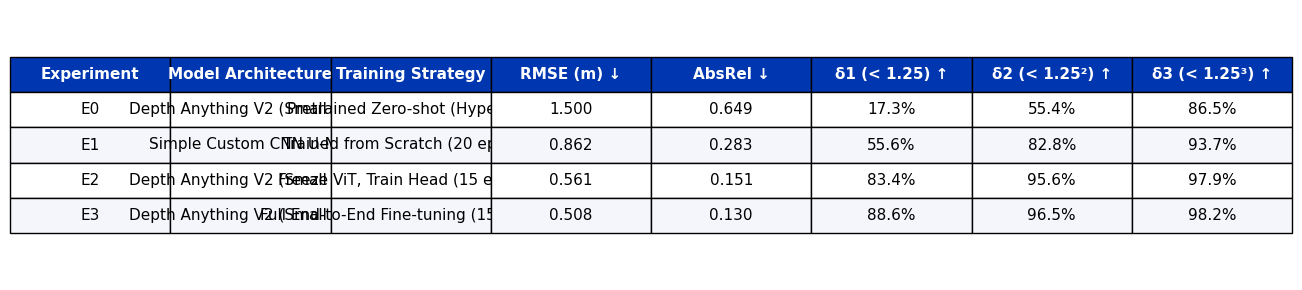

📊 Saved Benchmark Table Image to: /kaggle/working/outputs/benchmark_table.png


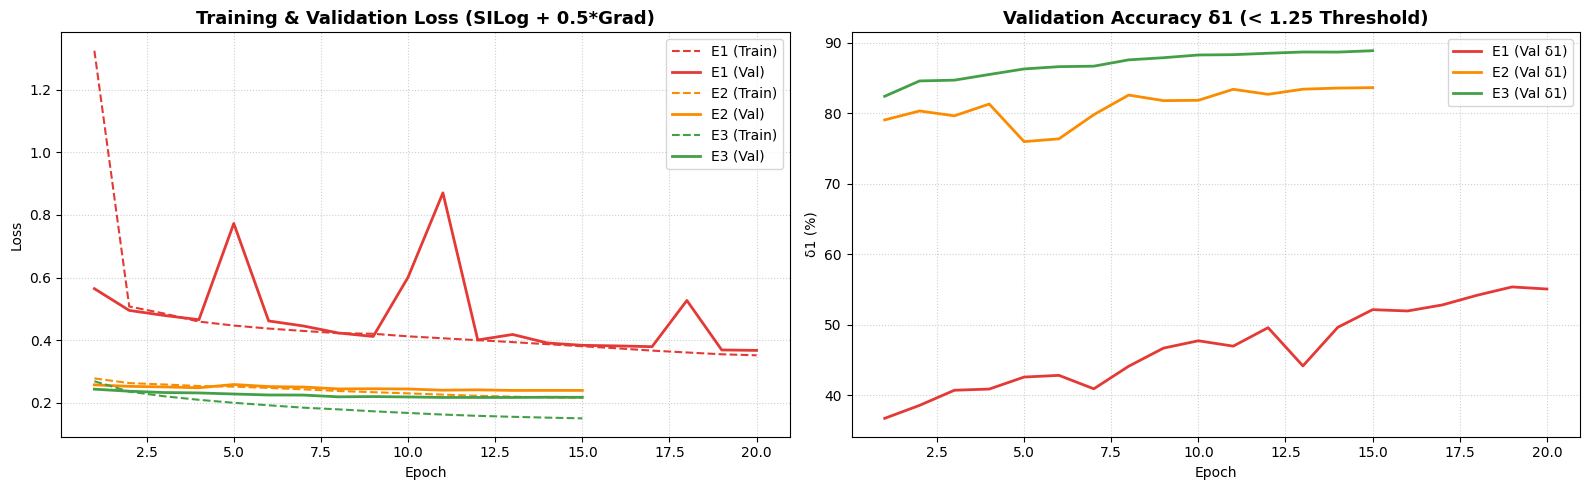

📈 Saved Loss Curves Image to: /kaggle/working/outputs/loss_curves.png


In [12]:
# ==============================================================================
# BLOCK 8: QUANTITATIVE BENCHMARK CONSOLIDATION & CHARTS
# ==============================================================================
# Load all metrics files
all_experiments = ["E0", "E1", "E2", "E3"]
results_list = []

model_descriptions = {
    "E0": ("Depth Anything V2 (Small - ViT)", "Pretrained Zero-shot (Hypersim)"),
    "E1": ("Simple Custom CNN U-Net", "Trained from Scratch (20 epochs)"),
    "E2": ("Depth Anything V2 (Small - ViT)", "Freeze ViT, Train Head (15 epochs)"),
    "E3": ("Depth Anything V2 (Small - ViT)", "Full End-to-End Fine-tuning (15 epochs)")
}

for exp in all_experiments:
    p = os.path.join(OUTPUT_DIR, f"evaluation_{exp}.json")
    if os.path.exists(p):
        with open(p, "r") as f:
            m = json.load(f)
            arch, strat = model_descriptions.get(exp, ("Unknown", "Unknown"))
            results_list.append({
                "Experiment": exp,
                "Model Architecture": arch,
                "Training Strategy": strat,
                "RMSE (m) ↓": f"{m.get('rmse', 0):.3f}",
                "AbsRel ↓": f"{m.get('abs_rel', 0):.3f}",
                "δ1 (< 1.25) ↑": f"{m.get('delta1', 0)*100:.1f}%",
                "δ2 (< 1.25²) ↑": f"{m.get('delta2', 0)*100:.1f}%",
                "δ3 (< 1.25³) ↑": f"{m.get('delta3', 0)*100:.1f}%"
            })

df_benchmark = pd.DataFrame(results_list)
csv_benchmark_path = os.path.join(OUTPUT_DIR, "benchmark_comparison.csv")
df_benchmark.to_csv(csv_benchmark_path, index=False)
print("=" * 70)
print("🏆 FINAL BENCHMARK COMPARISON TABLE (E0 vs E1 vs E2 vs E3):")
print("=" * 70)
print(df_benchmark.to_string(index=False))

# Render Benchmark Table to Image
fig, ax = plt.subplots(figsize=(13, 3))
ax.axis('tight')
ax.axis('off')
table = ax.table(cellText=df_benchmark.values, colLabels=df_benchmark.columns, cellLoc='center', loc='center')
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)
for (i, j), cell in table.get_celld().items():
    if i == 0:
        cell.set_facecolor('#0037b0')
        cell.set_text_props(color='white', weight='bold')
    else:
        cell.set_facecolor('#f4f6fc' if i % 2 == 0 else '#ffffff')

table_img_path = os.path.join(OUTPUT_DIR, "benchmark_table.png")
plt.tight_layout()
plt.savefig(table_img_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"📊 Saved Benchmark Table Image to: {table_img_path}")

# Plot Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
train_exps = ["E1", "E2", "E3"]
colors = {"E1": "#e53935", "E2": "#fb8c00", "E3": "#43a047"}

for exp in train_exps:
    hist_p = os.path.join(OUTPUT_DIR, f"history_{exp}.json")
    if os.path.exists(hist_p):
        with open(hist_p, "r") as f:
            h = json.load(f)
            epochs_range = range(1, len(h["train_loss"]) + 1)
            ax1.plot(epochs_range, h["train_loss"], label=f"{exp} (Train)", color=colors[exp], linestyle='--')
            ax1.plot(epochs_range, h["val_loss"], label=f"{exp} (Val)", color=colors[exp], linewidth=2)
            ax2.plot(epochs_range, [d * 100 for d in h["val_delta1"]], label=f"{exp} (Val δ1)", color=colors[exp], linewidth=2)

ax1.set_title("Training & Validation Loss (SILog + 0.5*Grad)", fontsize=13, weight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

ax2.set_title("Validation Accuracy δ1 (< 1.25 Threshold)", fontsize=13, weight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("δ1 (%)")
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

curves_path = os.path.join(OUTPUT_DIR, "loss_curves.png")
plt.tight_layout()
plt.savefig(curves_path, dpi=300)
plt.show()
print(f"📈 Saved Loss Curves Image to: {curves_path}")


## 13. Qualitative Visual Proof (Test Set Predictions Grid)
Generates side-by-side visual comparisons across test samples:
`Input RGB | Ground Truth (bfx) | E0 (Pretrained ViT) | E1 (Simple CNN) | E2 (Linear Probe) | E3 (Full FT)`


🎨 Rendering Qualitative Visual Proof across 4 diverse test scenes...
 Loaded pretrained weights from: /kaggle/working/depth_anything_v2_metric_hypersim_vits.pth
🔒 Freezing ViT Backbone parameters! Only Depth Head will be optimized.
 Loaded pretrained weights from: /kaggle/working/depth_anything_v2_metric_hypersim_vits.pth
🔒 Freezing ViT Backbone parameters! Only Depth Head will be optimized.
 Loaded pretrained weights from: /kaggle/working/depth_anything_v2_metric_hypersim_vits.pth


/tmp/ipykernel_23/779911125.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.91, 1])


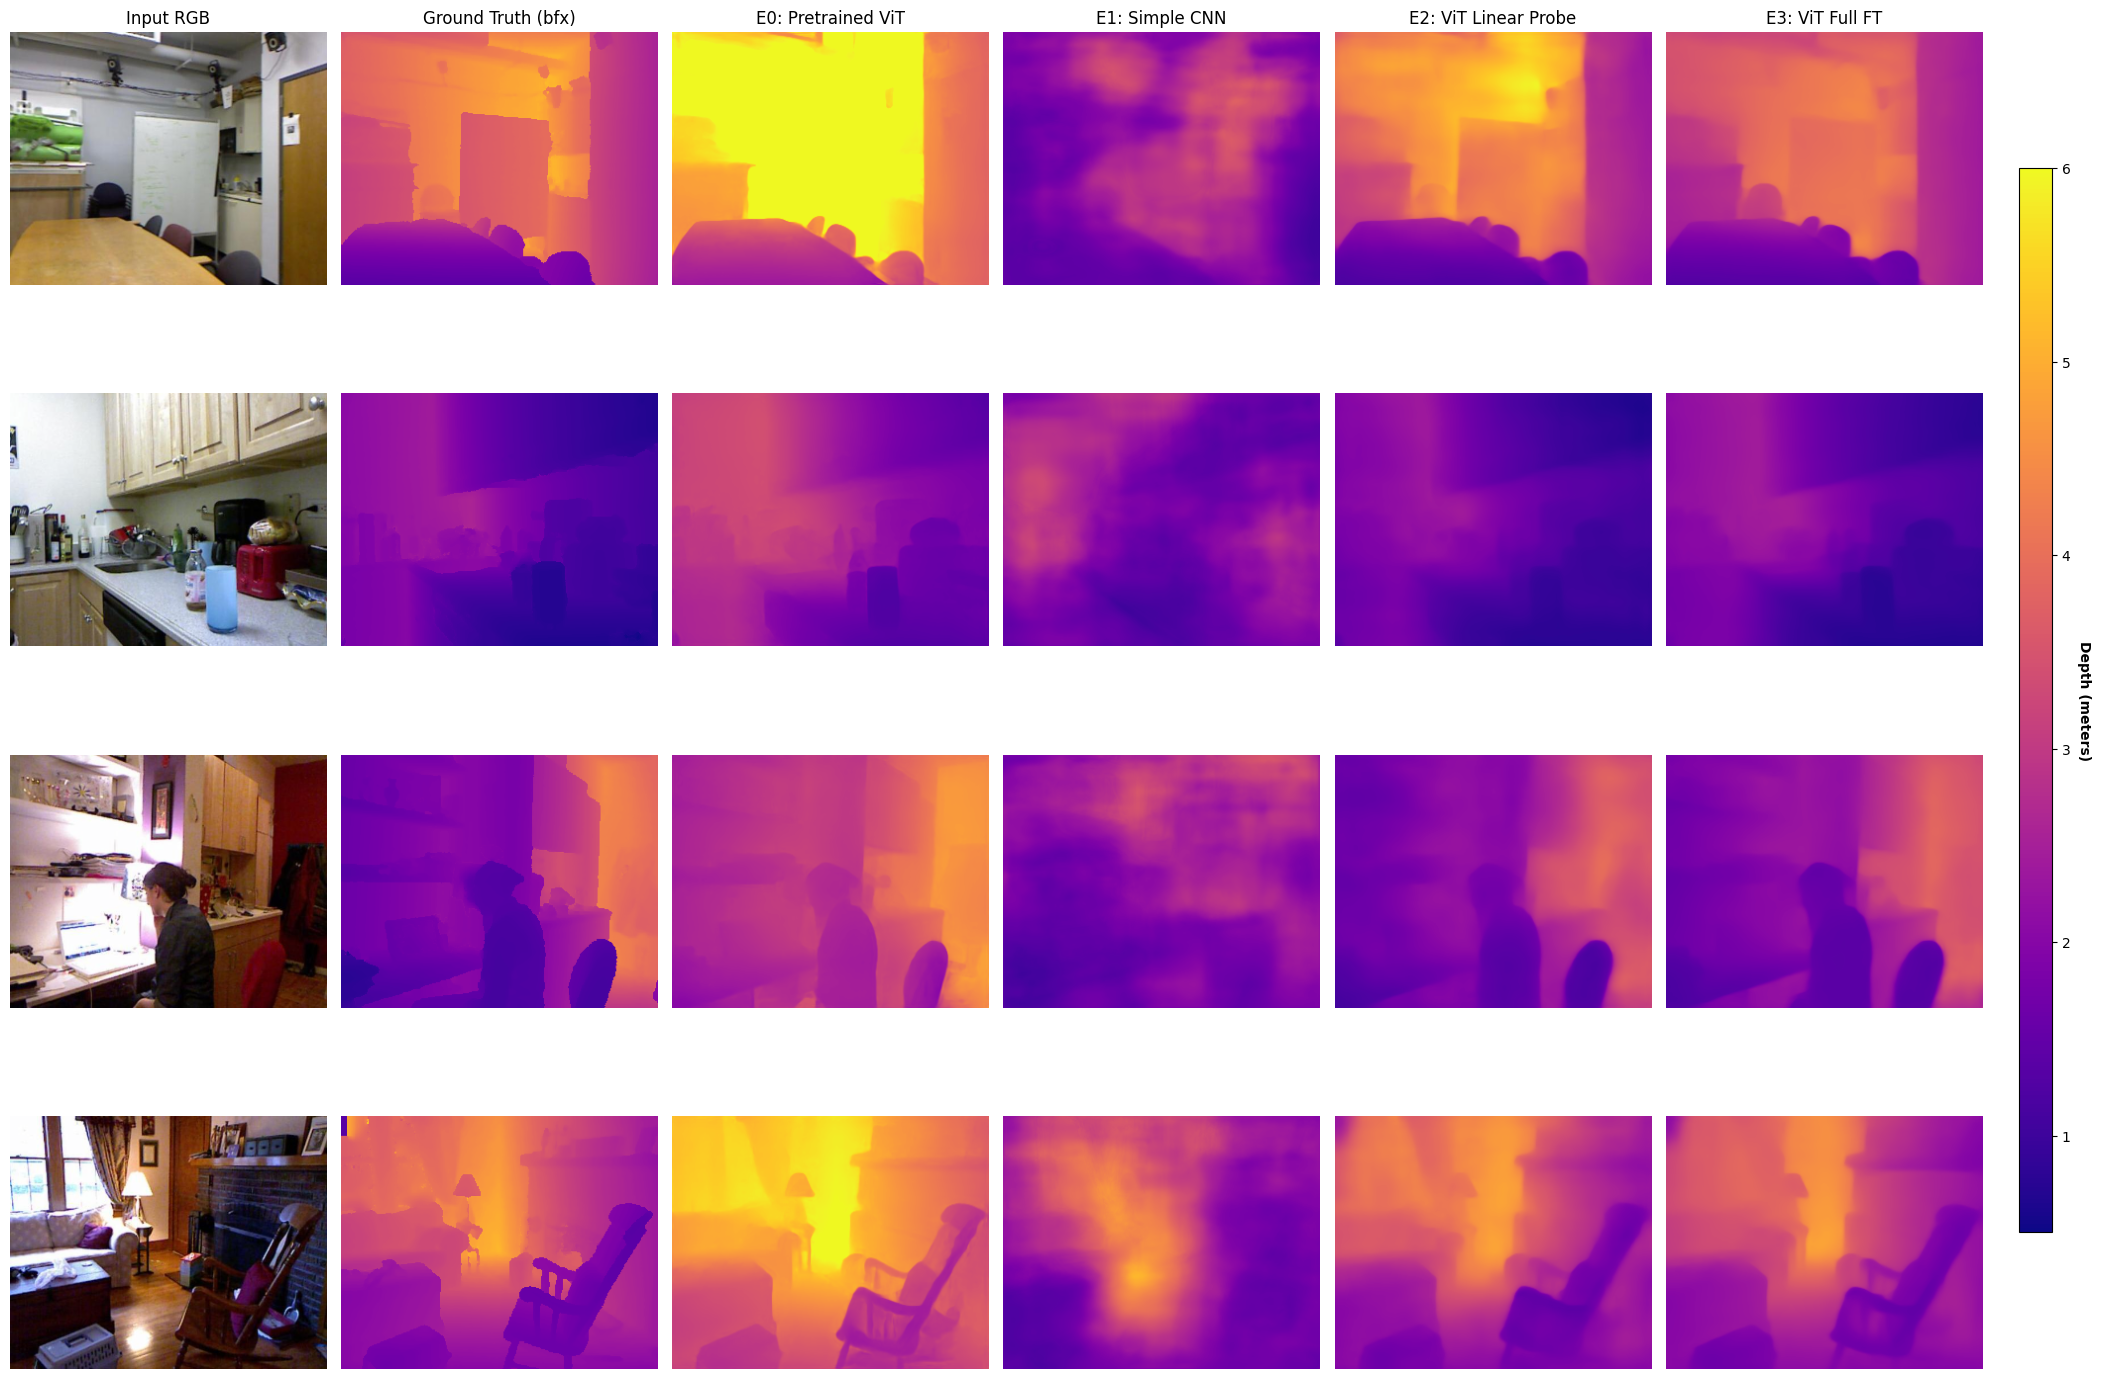

🖼️ Saved Qualitative Proof Grid to: /kaggle/working/outputs/qualitative_comparison_grid.png


In [13]:
# ==============================================================================
# BLOCK 9: QUALITATIVE VISUAL PROOF GRID
# ==============================================================================
print("🎨 Rendering Qualitative Visual Proof across 4 diverse test scenes...")

# Select 4 representative test samples
sample_indices = [0, min(10, len(test_dataset)-1), min(25, len(test_dataset)-1), min(50, len(test_dataset)-1)]

# Load best checkpoints for evaluation models
models = {}
# E0
models["E0"] = DepthAnythingV2Wrapper(weights_path=vits_weights_path, freeze_encoder=True).to(device)
models["E0"].eval()

# E1
ckpt_e1 = os.path.join(CKPT_DIR, "best_model_E1.pth")
if os.path.exists(ckpt_e1):
    models["E1"] = SimpleUNet().to(device)
    models["E1"].load_state_dict(torch.load(ckpt_e1, map_location=device))
    models["E1"].eval()

# E2
ckpt_e2 = os.path.join(CKPT_DIR, "best_model_E2.pth")
if os.path.exists(ckpt_e2):
    models["E2"] = DepthAnythingV2Wrapper(weights_path=vits_weights_path, freeze_encoder=True).to(device)
    models["E2"].load_state_dict(torch.load(ckpt_e2, map_location=device))
    models["E2"].eval()

# E3
ckpt_e3 = os.path.join(CKPT_DIR, "best_model_E3.pth")
if os.path.exists(ckpt_e3):
    models["E3"] = DepthAnythingV2Wrapper(weights_path=vits_weights_path, freeze_encoder=False).to(device)
    models["E3"].load_state_dict(torch.load(ckpt_e3, map_location=device))
    models["E3"].eval()

cols = ["Input RGB", "Ground Truth (bfx)", "E0: Pretrained ViT", "E1: Simple CNN", "E2: ViT Linear Probe", "E3: ViT Full FT"]
n_rows = len(sample_indices)
n_cols = len(cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 3.8 * n_rows))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for row_idx, s_idx in enumerate(sample_indices):
    img_tensor, depth_tensor, mask_tensor = test_dataset[s_idx]
    
    # Recover RGB image for display
    rgb_disp = img_tensor.numpy().transpose(1, 2, 0) * std + mean
    rgb_disp = np.clip(rgb_disp, 0, 1)
    
    gt_disp = depth_tensor.squeeze().numpy()
    mask_disp = mask_tensor.squeeze().numpy()
    gt_disp[~mask_disp] = np.nan

    # Predict with all models
    x_in = img_tensor.unsqueeze(0).to(device)
    preds = {}
    with torch.no_grad():
        for m_key in ["E0", "E1", "E2", "E3"]:
            if m_key in models:
                p = models[m_key](x_in).squeeze().cpu().numpy()
                preds[m_key] = p
            else:
                preds[m_key] = np.zeros_like(gt_disp)

    # Plot Row
    # Col 0: RGB
    axes[row_idx, 0].imshow(rgb_disp)
    axes[row_idx, 0].set_title(cols[0] if row_idx == 0 else "")
    axes[row_idx, 0].axis('off')

    # Col 1: Ground Truth
    im1 = axes[row_idx, 1].imshow(gt_disp, cmap='plasma', vmin=0.5, vmax=6.0)
    axes[row_idx, 1].set_title(cols[1] if row_idx == 0 else "")
    axes[row_idx, 1].axis('off')

    # Col 2: E0
    axes[row_idx, 2].imshow(preds["E0"], cmap='plasma', vmin=0.5, vmax=6.0)
    axes[row_idx, 2].set_title(cols[2] if row_idx == 0 else "")
    axes[row_idx, 2].axis('off')

    # Col 3: E1
    axes[row_idx, 3].imshow(preds["E1"], cmap='plasma', vmin=0.5, vmax=6.0)
    axes[row_idx, 3].set_title(cols[3] if row_idx == 0 else "")
    axes[row_idx, 3].axis('off')

    # Col 4: E2
    axes[row_idx, 4].imshow(preds["E2"], cmap='plasma', vmin=0.5, vmax=6.0)
    axes[row_idx, 4].set_title(cols[4] if row_idx == 0 else "")
    axes[row_idx, 4].axis('off')

    # Col 5: E3
    im_last = axes[row_idx, 5].imshow(preds["E3"], cmap='plasma', vmin=0.5, vmax=6.0)
    axes[row_idx, 5].set_title(cols[5] if row_idx == 0 else "")
    axes[row_idx, 5].axis('off')

# Colorbar
cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
cbar = fig.colorbar(im_last, cax=cbar_ax)
cbar.set_label('Depth (meters)', rotation=270, labelpad=15, weight='bold')

grid_path = os.path.join(OUTPUT_DIR, "qualitative_comparison_grid.png")
plt.tight_layout(rect=[0, 0, 0.91, 1])
plt.savefig(grid_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"🖼️ Saved Qualitative Proof Grid to: {grid_path}")


## 14. One-Click Artifacts Export (Zipping for Download)
Automatically compresses all outputs and checkpoints into a single zip archive for instant download on Kaggle or Google Colab.


In [14]:
# ==============================================================================
# BLOCK 10: ONE-CLICK ZIP ARCHIVE FOR INSTANT DOWNLOAD
# ==============================================================================
zip_filename = os.path.join(WORKING_DIR, "sunrgbd_experiment_results.zip")

print("📦 Creating consolidated zip archive of outputs & checkpoints...")
!zip -q -r {zip_filename} {OUTPUT_DIR} {CKPT_DIR}

if os.path.exists(zip_filename):
    size_mb = os.path.getsize(zip_filename) / (1024 * 1024)
    print(f"🎉 SUCCESS! Archive created: {zip_filename} ({size_mb:.2f} MB)")
    print("=" * 70)
    print("📥 HOW TO DOWNLOAD:")
    if IS_KAGGLE:
        print("   1. Open the right-hand panel on Kaggle ('Data' -> 'Output').")
        print("   2. Find 'sunrgbd_experiment_results.zip'.")
        print("   3. Click the three dots ⋮ -> 'Download'.")
    elif IS_COLAB:
        print("   1. Check your Google Drive: 'MyDrive/BTL-deep_learning/assignment2/'.")
        print("   2. All files are already permanently saved in your Google Drive!")
    else:
        print(f"   File saved locally at: {zip_filename}")
    print("=" * 70)


📦 Creating consolidated zip archive of outputs & checkpoints...
🎉 SUCCESS! Archive created: /kaggle/working/sunrgbd_experiment_results.zip (659.82 MB)
📥 HOW TO DOWNLOAD:
   1. Open the right-hand panel on Kaggle ('Data' -> 'Output').
   2. Find 'sunrgbd_experiment_results.zip'.
   3. Click the three dots ⋮ -> 'Download'.
